In [20]:

# AYARLAR VE VERİ YÜKLEME
import os
import random

random.seed(42)    

veri_setleri = {
    "veri_seti_1": "../data/veri_seti_1",   # klasör sınıflandırmalı (bird / drone klasörleri)
    "veri_seti_2": "../data/veri_seti_2",   # etiket dosyaları (.txt) ayrı klasörde
    "veri_seti_3": "../data/veri_seti_3",   # YOLOv8 formatı (train / valid / test)
}
resim_uzantilari = (".png", ".jpg", ".jpeg")

resimler = {}    # her veri setinin resim yollarının listesi
for isim, yol in veri_setleri.items():
    resimler[isim] = []
    if not os.path.exists(yol):
        print("UYARI: klasör bulunamadı", yol)
        continue
    for root, dirs, files in os.walk(yol):
        for file in files:
            if file.lower().endswith(resim_uzantilari):
                resimler[isim].append(os.path.join(root, file))
    print(isim, "->", len(resimler[isim]), "resim")

print("\n SINIF ADI DOSYALARI ")
# SINIF ADI DOSYALARINI GÖSTER
for isim, yol in veri_setleri.items():
    for root, dirs, files in os.walk(yol):
        for file in files:
            if file.lower() in ("classes.txt", "data.yaml", "data.yml"):
                print(f" {isim} / {file} ")
                dosya = open(os.path.join(root, file), encoding="utf-8")
                print(dosya.read())
                dosya.close()

print("\n ETİKET DOSYALARI KONTROLÜ ")
# ETİKET DOSYALARINI BUL
etiket_yolu = {}    # resim yolu, etiket (.txt) dosyasının yolu (yoksa None)

for isim in veri_setleri:
    bulunan = 0
    for resim in resimler[isim]:
        ayni_klasor = os.path.splitext(resim)[0] + ".txt"                       
        labels_klasoru = ayni_klasor.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
        
        # Veri Seti 2'nin klasör yapısı için özel düzeltme:
        ozel_birds = ayni_klasor.replace("images_birds", "labels_birds")
        ozel_drones = ayni_klasor.replace("images_drones", "labels_drones")

        if os.path.exists(ayni_klasor):
            etiket_yolu[resim] = ayni_klasor
            bulunan += 1
        elif os.path.exists(labels_klasoru):
            etiket_yolu[resim] = labels_klasoru
            bulunan += 1
        elif os.path.exists(ozel_birds):
            etiket_yolu[resim] = ozel_birds
            bulunan += 1
        elif os.path.exists(ozel_drones):
            etiket_yolu[resim] = ozel_drones
            bulunan += 1
        else:
            etiket_yolu[resim] = None
            
    print(isim, "->", len(resimler[isim]), "resimden", bulunan, "tanesinin etiket dosyası bulundu")
def kutulari_oku(etiket_dosyasi):
    """Etiket dosyasını okur. Her nesne için (sinif_no, x, y, genislik, yukseklik) listesi döndürür."""
    kutular = []
    dosya = open(etiket_dosyasi, encoding="utf-8")
    satirlar = dosya.read().splitlines()
    dosya.close()
    for satir in satirlar:
        parcalar = satir.split()
        if len(parcalar) == 5:                      # normal kutu etiketi
            kutular.append((int(float(parcalar[0])), float(parcalar[1]), float(parcalar[2]),
                            float(parcalar[3]), float(parcalar[4])))
        elif len(parcalar) > 5:                     # çokgen etiketi: köşe noktalarından kutu hesapla
            sayilar = parcalar[1:]
            xler = []
            yler = []
            for i in range(0, len(sayilar) - 1, 2):
                xler.append(float(sayilar[i]))
                yler.append(float(sayilar[i + 1]))
            kutular.append((int(float(parcalar[0])), (min(xler) + max(xler)) / 2, (min(yler) + max(yler)) / 2,
                            max(xler) - min(xler), max(yler) - min(yler)))
    return kutular

veri_seti_1 -> 4104 resim
veri_seti_2 -> 17936 resim
veri_seti_3 -> 6029 resim

 SINIF ADI DOSYALARI 
 veri_seti_3 / data.yaml 
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Bird', 'Drone']

roboflow:
  workspace: drone-vs-bird-4idpt
  project: drone-vs-bird-v3
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/drone-vs-bird-4idpt/drone-vs-bird-v3/dataset/3

 ETİKET DOSYALARI KONTROLÜ 
veri_seti_1 -> 4104 resimden 0 tanesinin etiket dosyası bulundu
veri_seti_2 -> 17936 resimden 17936 tanesinin etiket dosyası bulundu
veri_seti_3 -> 6029 resimden 6029 tanesinin etiket dosyası bulundu


In [21]:
# VERİ SETİ GENEL ÖZELLİKLERİ
from PIL import Image

# Etiket numarası -> sınıf adı (0: Bird, 1: Drone olarak doğrulandı)
sinif_adlari = {
    "veri_seti_2": {0: "bird", 1: "drone"},
    "veri_seti_3": {0: "bird", 1: "drone"},
}

sonuc = {}              # raporda ve grafiklerde kullanacağım değerler
sinif_resimleri = {}    # veri seti -> {"bird": [yollar], "drone": [yollar]}
bozuk_listesi = []      # bozuk dosyaların yolları

print(" VERİ SETİ GENEL ÖZELLİKLERİ")

for isim, yol in veri_setleri.items():
    liste = resimler[isim]
    if len(liste) == 0:
        continue

    kus_sayisi = 0
    drone_sayisi = 0
    sinifsiz_sayisi = 0
    kutu_sayisi = 0
    egitim_sayisi = 0
    dogrulama_sayisi = 0
    test_sayisi = 0
    etiketli = 0
    etiketsiz = 0
    bozuk = 0
    formatlar = []
    min_gen = 100000
    max_gen = 0
    min_yuk = 100000
    max_yuk = 0
    sinif_resimleri[isim] = {"bird": [], "drone": []}

    for resim in liste:
        goreli = os.path.dirname(resim)[len(yol):].lower()

        # Format
        uzanti = os.path.splitext(resim)[1].lower().replace(".", "")
        if uzanti not in formatlar:
            formatlar.append(uzanti)

        # Eğitim / doğrulama / test
        if "train" in goreli:
            egitim_sayisi += 1
        elif "valid" in goreli or "val" in goreli:
            dogrulama_sayisi += 1
        elif "test" in goreli:
            test_sayisi += 1

        # Sınıf: önce klasör adından
        sinif = None
        if "bird" in goreli:
            sinif = "bird"
        elif "drone" in goreli:
            sinif = "drone"

        # Etiket dosyası
        if etiket_yolu[resim] is not None:
            kutular = kutulari_oku(etiket_yolu[resim])
            if len(kutular) > 0:
                etiketli += 1
                kutu_sayisi += len(kutular)
                if sinif is None:                              
                    sinif_no = kutular[0][0]
                    if isim in sinif_adlari and sinif_no in sinif_adlari[isim]:
                        sinif = sinif_adlari[isim][sinif_no]
            else:
                etiketsiz += 1                                 
        else:
            etiketsiz += 1                                     

        # Sınıf sayaçları
        if sinif == "bird":
            kus_sayisi += 1
            sinif_resimleri[isim]["bird"].append(resim)
        elif sinif == "drone":
            drone_sayisi += 1
            sinif_resimleri[isim]["drone"].append(resim)
        else:
            sinifsiz_sayisi += 1

        # Boyut ve bozuk dosya kontrolü
        try:
            with Image.open(resim) as img:
                gen = img.width
                yuk = img.height
                img.verify()                                   
            if gen < min_gen: min_gen = gen
            if gen > max_gen: max_gen = gen
            if yuk < min_yuk: min_yuk = yuk
            if yuk > max_yuk: max_yuk = yuk
        except Exception:
            bozuk += 1
            bozuk_listesi.append(resim)

    sonuc[isim] = {"toplam": len(liste), "bird": kus_sayisi, "drone": drone_sayisi, "sinifsiz": sinifsiz_sayisi,
                   "egitim": egitim_sayisi, "dogrulama": dogrulama_sayisi, "test": test_sayisi,
                   "bozuk": bozuk, "etiketli": etiketli, "etiketsiz": etiketsiz, "kutu": kutu_sayisi}

    print(f"\n {isim} \n")
    print(f"Toplam Veri Sayısı: {len(liste)}")
    print(f"Veri Formatı: {', '.join(formatlar)}")
    print(f"Veri Boyutu: genişlik {min_gen}–{max_gen}, yükseklik {min_yuk}–{max_yuk}")
    if egitim_sayisi > 0 or dogrulama_sayisi > 0 or test_sayisi > 0:
        print(f"Dağılım: Eğitim: {egitim_sayisi} | Doğrulama: {dogrulama_sayisi} | Test: {test_sayisi}")
    else:
        print("Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)")
    print(f"Sınıf Sayısı: {int(kus_sayisi > 0) + int(drone_sayisi > 0)}")
    print(f"Sınıflara Göre Veri Dağılımı: Kuş (Bird): {kus_sayisi} | İHA (Drone): {drone_sayisi} | Belirlenemeyen: {sinifsiz_sayisi}")
    print(f"Eksik/Bozuk Veri: {bozuk} bozuk görsel, {etiketsiz} resimde etiket yok veya boş")
    if etiketli == 0:
        print("Etiket Durumu: Etiket dosyası yok (sınıf klasör adından alınıyor)")
    else:
        print(f"Etiket Durumu: {etiketli} resimde etiket var, toplam {kutu_sayisi} nesne (kutu)")

 VERİ SETİ GENEL ÖZELLİKLERİ

 veri_seti_1 

Toplam Veri Sayısı: 4104
Veri Formatı: jpg, jpeg, png
Veri Boyutu: genişlik 163–4633, yükseklik 114–3089
Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)
Sınıf Sayısı: 2
Sınıflara Göre Veri Dağılımı: Kuş (Bird): 1605 | İHA (Drone): 2499 | Belirlenemeyen: 0
Eksik/Bozuk Veri: 0 bozuk görsel, 4104 resimde etiket yok veya boş
Etiket Durumu: Etiket dosyası yok (sınıf klasör adından alınıyor)

 veri_seti_2 

Toplam Veri Sayısı: 17936
Veri Formatı: png
Veri Boyutu: genişlik 640–640, yükseklik 640–640
Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)
Sınıf Sayısı: 2
Sınıflara Göre Veri Dağılımı: Kuş (Bird): 8936 | İHA (Drone): 9000 | Belirlenemeyen: 0
Eksik/Bozuk Veri: 0 bozuk görsel, 0 resimde etiket yok veya boş
Etiket Durumu: 17936 resimde etiket var, toplam 20664 nesne (kutu)

 veri_seti_3 

Toplam Veri Sayısı: 6029
Veri Formatı: jpg
Veri Boyutu: genişlik 640–640, yükseklik 640–640
Dağılım: Eğitim: 5397 | Doğrulama: 379 

In [22]:
# KONTROL 1: VERİ ÇOĞALTMA VE BENZER DOSYA ADLARI
print(" VERİ KALİTESİ KONTROLLERİ")

artirma_izleri = ["_r90", "_r180", "_r270", "_darker", "_brighter", "_blur", "_noise"] # veri artırma yöntemleri uygulananları bulmak sızıntıyı engellemek için 

for isim in veri_setleri:
    izli = 0
    ucak_adli = 0
    ucak_ornekleri = []
    for resim in resimler[isim]:
        dosya_adi = os.path.basename(resim).lower()
        for iz in artirma_izleri:
            if iz in dosya_adi:
                izli += 1
                break
        if "plane" in dosya_adi:
            ucak_adli += 1
            if len(ucak_ornekleri) < 3:
                ucak_ornekleri.append(resim)
    print(f"{isim}: Çoğaltma izli dosya adı: {izli} / {len(resimler[isim])} | Adında 'plane' geçen: {ucak_adli}")
    for ornek in ucak_ornekleri:
        print("    Örnek:", ornek)

# KONTROL 2: AYNI VİDEODAN GELEN KARELER (Veri Sızıntısı Kontrolü)
for isim in veri_setleri:
    video_bolumleri = {}
    for resim in resimler[isim]:
        dosya_adi = os.path.basename(resim)
        if not dosya_adi.lower().startswith("video"):
            continue
        video = dosya_adi.split("_")[0]
        goreli = os.path.dirname(resim)[len(veri_setleri[isim]):].lower()
        bolum = "diger"
        if "train" in goreli:
            bolum = "train"
        elif "valid" in goreli or "val" in goreli:
            bolum = "valid"
        elif "test" in goreli:
            bolum = "test"
        if video not in video_bolumleri:
            video_bolumleri[video] = []
        if bolum not in video_bolumleri[video]:
            video_bolumleri[video].append(bolum)

    if len(video_bolumleri) == 0:
        print(f"{isim}: Dosya adları 'video...' ile başlamıyor, bu kontrol uygulanmadı.")
    else:
        karisik = 0
        for video in video_bolumleri:
            if len(video_bolumleri[video]) > 1:
                karisik += 1
        print(f"{isim}: {len(video_bolumleri)} farklı video, bunların {karisik} tanesi birden fazla bölümde (train/valid/test) görünüyor.")


# KONTROL 3: BİREBİR AYNI DOSYALAR (MD5) FARKLI VERİ SETLERİNDE AYNI GÖRÜNTÜ FARKLI İSİMLERDE OLSA BİLE PİKSELLERİNE BAKARAK AYNI FOTO OLUP OLMADIĞINI ANLAMA KONTROL ETME 
import hashlib

gorulen = {}
ic_kopya = {}
capraz_kopya = {}

for isim in veri_setleri:
    ic_kopya[isim] = 0
    for resim in resimler[isim]:
        dosya = open(resim, "rb")
        md5 = hashlib.md5(dosya.read()).hexdigest()
        dosya.close()
        if md5 in gorulen:
            if gorulen[md5] == isim:
                ic_kopya[isim] += 1
            else:
                cift = gorulen[md5] + " - " + isim
                if cift not in capraz_kopya:
                    capraz_kopya[cift] = 0
                capraz_kopya[cift] += 1
        else:
            gorulen[md5] = isim

print("Veri seti içi birebir kopya sayıları:", ic_kopya)
print("Veri setleri arası ortak resim sayıları:", capraz_kopya)


 VERİ KALİTESİ KONTROLLERİ
veri_seti_1: Çoğaltma izli dosya adı: 760 / 4104 | Adında 'plane' geçen: 165
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_1.jpg
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_10.jpg
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_11.jpg
veri_seti_2: Çoğaltma izli dosya adı: 0 / 17936 | Adında 'plane' geçen: 0
veri_seti_3: Çoğaltma izli dosya adı: 0 / 6029 | Adında 'plane' geçen: 0
veri_seti_1: 4 farklı video, bunların 0 tanesi birden fazla bölümde (train/valid/test) görünüyor.
veri_seti_2: Dosya adları 'video...' ile başlamıyor, bu kontrol uygulanmadı.
veri_seti_3: 97 farklı video, bunların 7 tanesi birden fazla bölümde (train/valid/test) görünüyor.
Veri seti içi birebir kopya sayıları: {'veri_seti_1': 412, 'veri_seti_2': 12, 'veri_seti_3': 585}
Veri setleri arası ortak resim sayıları: {}


Görsel 1 (Örnek Resimler) oluşturuldu ve kaydedildi.


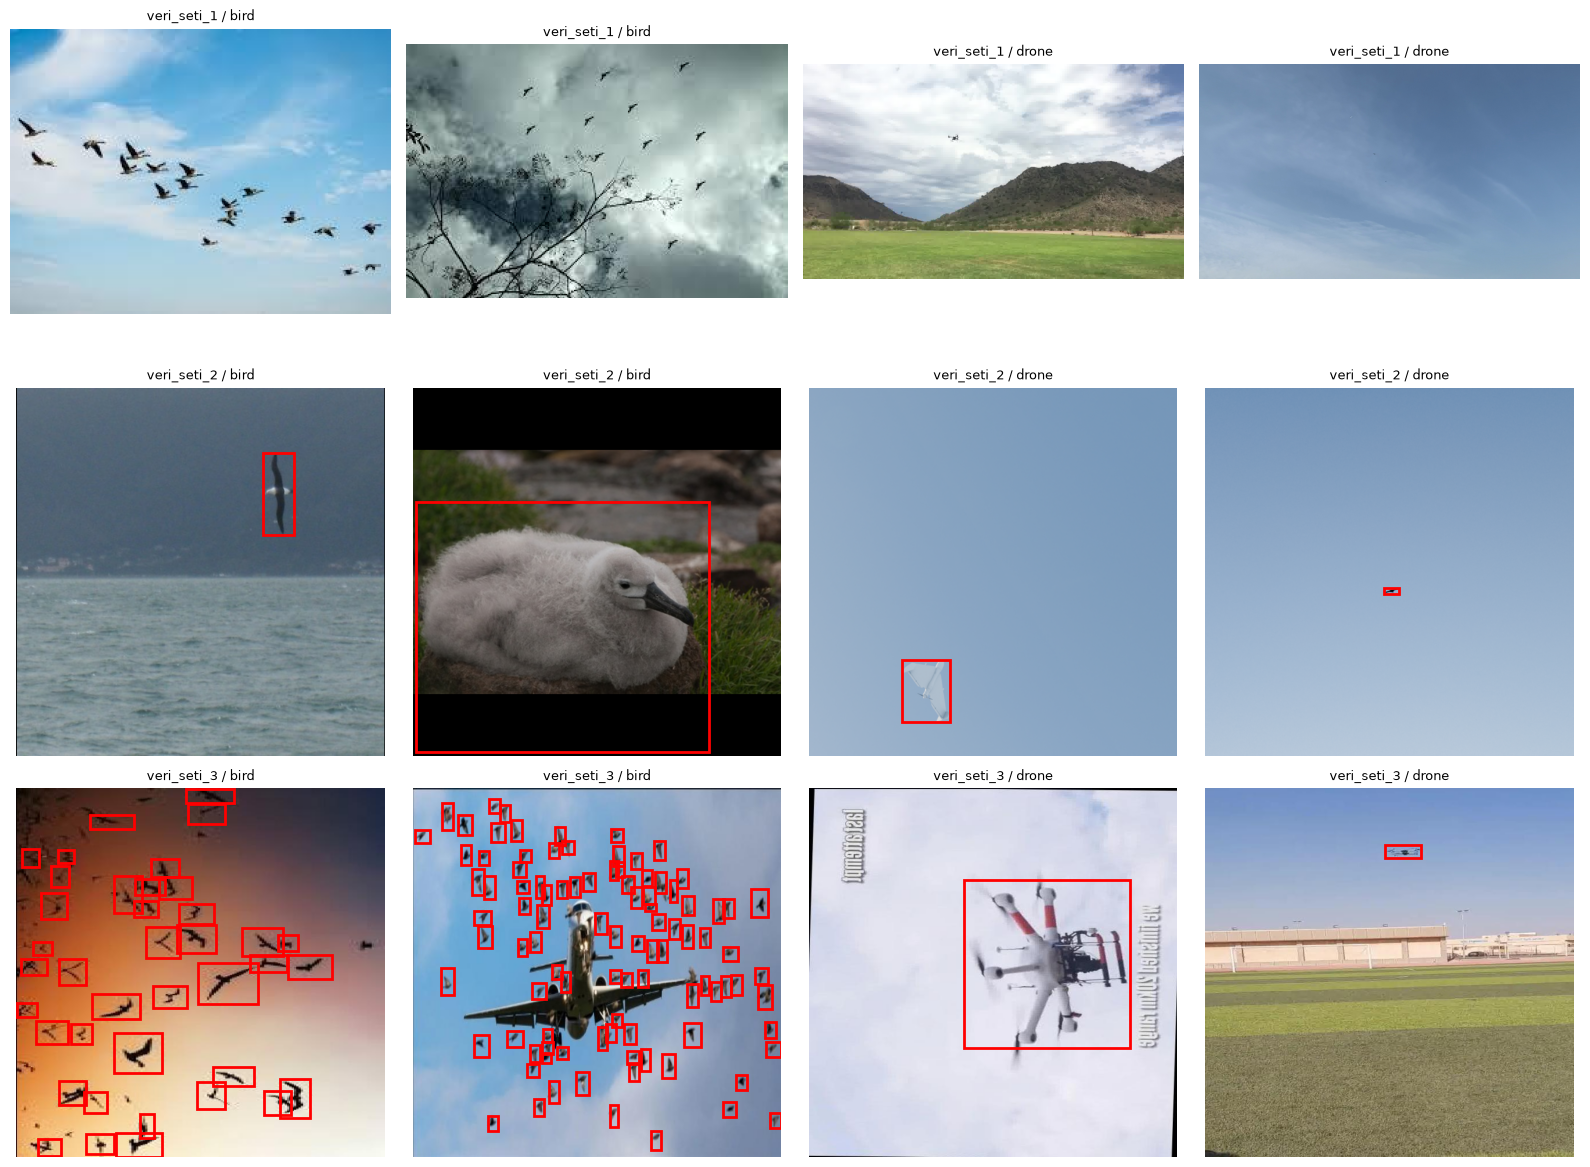

Görsel 2 (Sınıf Dağılımı) oluşturuldu ve kaydedildi.


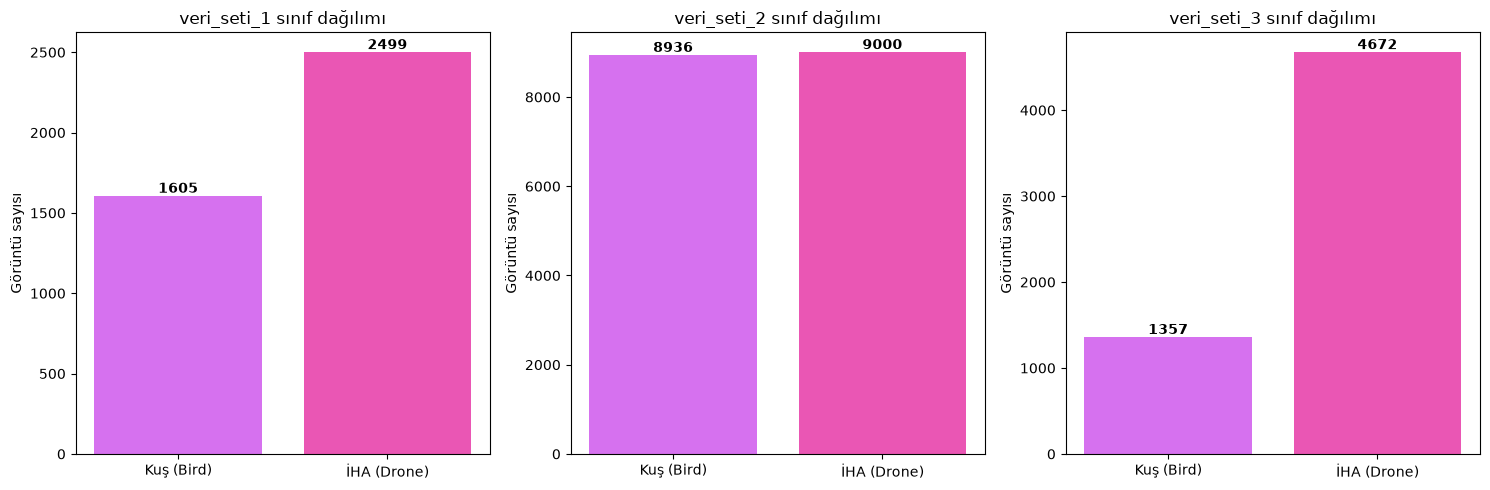

Görsel 3 (Bölünme Dağılımı) oluşturuldu ve kaydedildi.


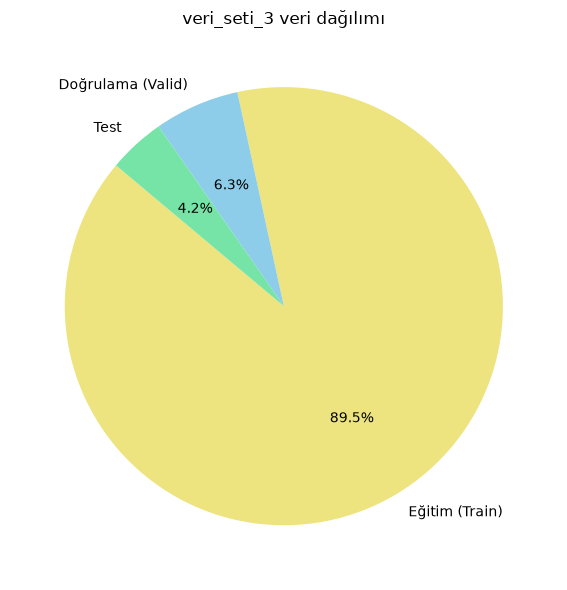

In [23]:
# GÖRSELLEŞTİRME 
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Görsellerin kaydedileceği klasör
os.makedirs("../rapor_gorselleri", exist_ok=True)

# VERİ SETLERİNDEN ÖRNEK
plt.figure(figsize=(16, 12))
satir_no = 0
for isim in sinif_resimleri:
    sutun_no = 0
    for sinif in ["bird", "drone"]:
        liste = sinif_resimleri[isim][sinif]
        secim = random.sample(liste, min(2, len(liste)))
        for resim in secim:
            plt.subplot(3, 4, satir_no * 4 + sutun_no + 1)
            img = Image.open(resim).convert("RGB")
            plt.imshow(img)
            plt.title(f"{isim} / {sinif}", fontsize=9)
            plt.axis("off")
            # etiket varsa kutuyu çiz (kırmızı)
            if etiket_yolu[resim] is not None:
                for sinif_no, x, y, w, h in kutulari_oku(etiket_yolu[resim]):
                    gen, yuk = img.size
                    sol = (x - w / 2) * gen
                    ust = (y - h / 2) * yuk
                    plt.gca().add_patch(Rectangle((sol, ust), w * gen, h * yuk, fill=False, edgecolor="red", linewidth=2))
            sutun_no += 1
    satir_no += 1

plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel1_ornek_resimler.png", dpi=150)
print("Görsel 1 (Örnek Resimler) oluşturuldu ve kaydedildi.")
plt.show()

# SINIF DAĞILIMI 
plt.figure(figsize=(5 * len(sonuc), 5))
sira = 1
for isim in sonuc:
    plt.subplot(1, len(sonuc), sira)
    siniflar = ["Kuş (Bird)", "İHA (Drone)"]
    sayilar = [sonuc[isim]["bird"], sonuc[isim]["drone"]]
    cubuklar = plt.bar(siniflar, sayilar, color=["#D15FEEE2", "#EA56B4"])
    plt.title(f"{isim} sınıf dağılımı")
    plt.ylabel("Görüntü sayısı")
    for cubuk in cubuklar:
        yukseklik = cubuk.get_height()
        plt.text(cubuk.get_x() + cubuk.get_width() / 2, yukseklik, str(int(yukseklik)), ha="center", va="bottom", fontweight="bold")
    sira += 1

plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel2_sinif_dagilimi.png", dpi=150)
print("Görsel 2 (Sınıf Dağılımı) oluşturuldu ve kaydedildi.")
plt.show()

# EĞİTİM / DOĞRULAMA / TEST DAĞILIMI 
bolunmus = []
for isim in sonuc:
    if sonuc[isim]["egitim"] + sonuc[isim]["dogrulama"] + sonuc[isim]["test"] > 0:
        bolunmus.append(isim)

if len(bolunmus) == 0:
    print("Hiçbir veri seti train/valid/test olarak bölünmemiş.")
else:
    plt.figure(figsize=(6 * len(bolunmus), 6))
    sira = 1
    for isim in bolunmus:
        plt.subplot(1, len(bolunmus), sira)
        sayilar = [sonuc[isim]["egitim"], sonuc[isim]["dogrulama"], sonuc[isim]["test"]]
        plt.pie(sayilar, labels=["Eğitim (Train)", "Doğrulama (Valid)", "Test"], autopct="%1.1f%%",
                colors=["#EDE47F", "#8ECDEA", "#76E3A7"], startangle=140)
        plt.title(f"{isim} veri dağılımı")
        sira += 1
    plt.tight_layout()
    plt.savefig("../rapor_gorselleri/gorsel3_egitim_test_dagilimi.png", dpi=150)
    print("Görsel 3 (Bölünme Dağılımı) oluşturuldu ve kaydedildi.")
    plt.show()

In [24]:
# ÖN İŞLEME (KIRPMA, BOYUTLANDIRMA, RGB)
import hashlib

print("RENK MODU ANALİZİ")
for isim in sinif_resimleri:
    for sinif in ["bird", "drone"]:
        modlar = {}
        for resim in sinif_resimleri[isim][sinif]:
            try:
                with Image.open(resim) as img:
                    mod = img.mode
                modlar[mod] = modlar.get(mod, 0) + 1
            except Exception:
                pass
        print(f"  {isim} / {sinif}: {modlar}")
print("RGBA / P gibi modlar ön işlemede RGB'ye çevrilecek.")

#kopya dosyaları eleme

md5_sozlugu = {}              # resim yolu -> md5
ilk_gorulen = {}              # md5 -> (ilk resim, veri seti)
temiz_kaynak_resimler = []    # (veri seti, resim yolu)
elenen = {}                   # veri seti -> {"artirma_izli": n, "ucak_adli": n, "kopya": n, "capraz_kopya": n}

for isim in veri_setleri:
    elenen[isim] = {"artirma_izli": 0, "ucak_adli": 0, "kopya": 0, "capraz_kopya": 0}
    for resim in resimler[isim]:
        dosya_adi = os.path.basename(resim).lower()
        izli = False
        for iz in artirma_izleri:
            if iz in dosya_adi:
                izli = True
        if izli:
            elenen[isim]["artirma_izli"] += 1
            continue
        if "plane" in dosya_adi:
            elenen[isim]["ucak_adli"] += 1
            continue
        try:
            dosya = open(resim, "rb")
            md5 = hashlib.md5(dosya.read()).hexdigest()
            dosya.close()
        except Exception:
            continue
        md5_sozlugu[resim] = md5
        if md5 in ilk_gorulen:
            elenen[isim]["kopya"] += 1
            if ilk_gorulen[md5][1] != isim:
                elenen[isim]["capraz_kopya"] += 1
            continue
        ilk_gorulen[md5] = (resim, isim)
        temiz_kaynak_resimler.append((isim, resim))

print("Elenen dosyalar:", elenen)
for isim in veri_setleri:
    sayi = 0
    for k_isim, k_resim in temiz_kaynak_resimler:
        if k_isim == isim:
            sayi += 1
    print(f"{isim}: {len(resimler[isim])} resimden {sayi} tanesi temiz kaynak resim olarak kaldı")
temiz_kume = set()
for k_isim, k_resim in temiz_kaynak_resimler:
    temiz_kume.add(k_resim)

RENK MODU ANALİZİ
  veri_seti_1 / bird: {'RGB': 1602, 'P': 3}
  veri_seti_1 / drone: {'RGB': 2499}
  veri_seti_2 / bird: {'RGB': 8936}
  veri_seti_2 / drone: {'RGBA': 9000}
  veri_seti_3 / bird: {'RGB': 1357}
  veri_seti_3 / drone: {'RGB': 4672}
RGBA / P gibi modlar ön işlemede RGB'ye çevrilecek.
Elenen dosyalar: {'veri_seti_1': {'artirma_izli': 760, 'ucak_adli': 165, 'kopya': 385, 'capraz_kopya': 0}, 'veri_seti_2': {'artirma_izli': 0, 'ucak_adli': 0, 'kopya': 12, 'capraz_kopya': 0}, 'veri_seti_3': {'artirma_izli': 0, 'ucak_adli': 0, 'kopya': 585, 'capraz_kopya': 0}}
veri_seti_1: 4104 resimden 2794 tanesi temiz kaynak resim olarak kaldı
veri_seti_2: 17936 resimden 17924 tanesi temiz kaynak resim olarak kaldı
veri_seti_3: 6029 resimden 5444 tanesi temiz kaynak resim olarak kaldı


SINIF TUTARLILIĞI (klasör adı / etiket numarasının sınıfı):
   veri_seti_2: bird klasörü / etiket sınıfı drone -> 11642
   veri_seti_2: drone klasörü / etiket sınıfı bird -> 9000

=== veri_seti_2: 11642 kuş, 9000 İHA nesnesi ===
Alan oranı (en küçük / medyan / en büyük):
  kuş : 0.00011 / 0.05572 / 0.98789
  İHA : 3e-05 / 0.00239 / 1.0

Kısa kenarı eşikten KÜÇÜK olduğu için ATILACAK nesneler:
eşik(px)   kuş atılan (%)      İHA atılan (%)
4          0        (  0.0%)   347      (  3.9%)
8          29       (  0.2%)   1987     ( 22.1%)
12         187      (  1.6%)   2814     ( 31.3%)
16         397      (  3.4%)   3451     ( 38.3%)
24         882      (  7.6%)   4585     ( 50.9%)
32         1406     ( 12.1%)   5590     ( 62.1%)

Alan oranı eşikten BÜYÜK olduğu için (yakın çekim) ATILACAK nesneler:
eşik    kuş atılan (%)      İHA atılan (%)
0.05    6103     ( 52.4%)   90       (  1.0%)
0.1     4257     ( 36.6%)   22       (  0.2%)
0.25    1776     ( 15.3%)   12       (  0.1%)
0.4     768 

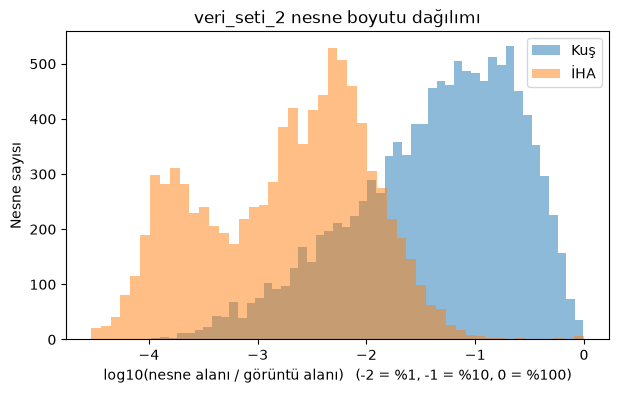


=== veri_seti_3: 12454 kuş, 5043 İHA nesnesi ===
Alan oranı (en küçük / medyan / en büyük):
  kuş : 0.0001 / 0.00269 / 0.85772
  İHA : 0.00028 / 0.00523 / 0.37547

Kısa kenarı eşikten KÜÇÜK olduğu için ATILACAK nesneler:
eşik(px)   kuş atılan (%)      İHA atılan (%)
4          0        (  0.0%)   0        (  0.0%)
8          132      (  1.1%)   0        (  0.0%)
12         1423     ( 11.4%)   28       (  0.6%)
16         2948     ( 23.7%)   162      (  3.2%)
24         5554     ( 44.6%)   850      ( 16.9%)
32         7564     ( 60.7%)   1765     ( 35.0%)

Alan oranı eşikten BÜYÜK olduğu için (yakın çekim) ATILACAK nesneler:
eşik    kuş atılan (%)      İHA atılan (%)
0.05    300      (  2.4%)   258      (  5.1%)
0.1     253      (  2.0%)   135      (  2.7%)
0.25    158      (  1.3%)   10       (  0.2%)
0.4     91       (  0.7%)   0        (  0.0%)
0.6     39       (  0.3%)   0        (  0.0%)


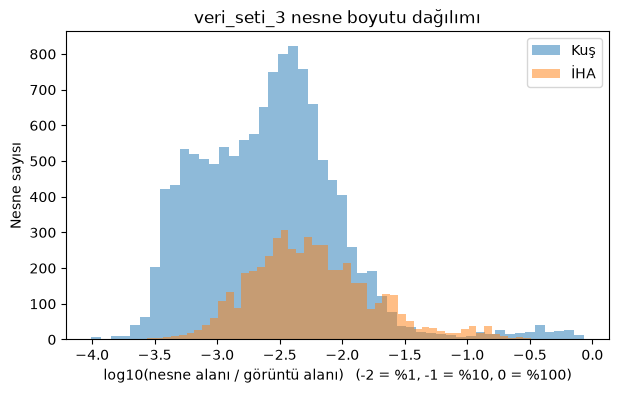

In [25]:
# NESNE BOYUTU ANALİZİ
import math
import matplotlib.pyplot as plt

nesneler = []        # [veri seti, sınıf, alan oranı, kısa kenar (piksel)]
sinif_uyumu = {}

for isim in ["veri_seti_2", "veri_seti_3"]:
    for resim in resimler[isim]:
        if resim not in temiz_kume or etiket_yolu[resim] is None:
            continue
        goreli = os.path.dirname(resim)[len(veri_setleri[isim]):].lower()
        klasor_sinifi = "bird" if "bird" in goreli else ("drone" if "drone" in goreli else None)
        with Image.open(resim) as img:
            gen, yuk = img.size
        for sinif_no, x, y, w, h in kutulari_oku(etiket_yolu[resim]):
            etiket_sinifi = sinif_adlari[isim].get(sinif_no)
            sinif = klasor_sinifi if klasor_sinifi is not None else etiket_sinifi
            if sinif is None:
                continue
            nesneler.append([isim, sinif, w * h, min(w * gen, h * yuk)])
            if klasor_sinifi is not None:
                anahtar = isim + ": " + klasor_sinifi + " klasörü / etiket sınıfı " + str(etiket_sinifi)
                sinif_uyumu[anahtar] = sinif_uyumu.get(anahtar, 0) + 1

print("SINIF TUTARLILIĞI (klasör adı / etiket numarasının sınıfı):")
for anahtar in sinif_uyumu:
    print("  ", anahtar, "->", sinif_uyumu[anahtar])

os.makedirs("../rapor_gorselleri", exist_ok=True)
for isim in ["veri_seti_2", "veri_seti_3"]:
    kus_alan = []; drone_alan = []; kus_kisa = []; drone_kisa = []
    for n in nesneler:
        if n[0] != isim:
            continue
        if n[1] == "bird":
            kus_alan.append(n[2]); kus_kisa.append(n[3])
        else:
            drone_alan.append(n[2]); drone_kisa.append(n[3])
    if len(kus_alan) == 0 or len(drone_alan) == 0:
        continue
    kus_alan.sort(); drone_alan.sort()
    print(f"\n=== {isim}: {len(kus_alan)} kuş, {len(drone_alan)} İHA nesnesi ===")
    print("Alan oranı (en küçük / medyan / en büyük):")
    print("  kuş :", round(kus_alan[0], 5), "/", round(kus_alan[len(kus_alan) // 2], 5), "/", round(kus_alan[-1], 5))
    print("  İHA :", round(drone_alan[0], 5), "/", round(drone_alan[len(drone_alan) // 2], 5), "/", round(drone_alan[-1], 5))

    print("\nKısa kenarı eşikten KÜÇÜK olduğu için ATILACAK nesneler:")
    print("eşik(px)   kuş atılan (%)      İHA atılan (%)")
    for esik in [4, 8, 12, 16, 24, 32]:
        kus_atilan = 0
        for k in kus_kisa:
            if k < esik:
                kus_atilan += 1
        drone_atilan = 0
        for k in drone_kisa:
            if k < esik:
                drone_atilan += 1
        print(f"{esik:<10} {kus_atilan:<8} ({100 * kus_atilan / len(kus_kisa):5.1f}%)   {drone_atilan:<8} ({100 * drone_atilan / len(drone_kisa):5.1f}%)")

    print("\nAlan oranı eşikten BÜYÜK olduğu için (yakın çekim) ATILACAK nesneler:")
    print("eşik    kuş atılan (%)      İHA atılan (%)")
    for esik in [0.05, 0.10, 0.25, 0.40, 0.60]:
        kus_atilan = 0
        for a in kus_alan:
            if a > esik:
                kus_atilan += 1
        drone_atilan = 0
        for a in drone_alan:
            if a > esik:
                drone_atilan += 1
        print(f"{esik:<7} {kus_atilan:<8} ({100 * kus_atilan / len(kus_alan):5.1f}%)   {drone_atilan:<8} ({100 * drone_atilan / len(drone_alan):5.1f}%)")

    kus_log = []
    for a in kus_alan:
        if a > 0:
            kus_log.append(math.log10(a))
    drone_log = []
    for a in drone_alan:
        if a > 0:
            drone_log.append(math.log10(a))
    plt.figure(figsize=(7, 4))
    plt.hist(kus_log, bins=50, alpha=0.5, label="Kuş")
    plt.hist(drone_log, bins=50, alpha=0.5, label="İHA")
    plt.xlabel("log10(nesne alanı / görüntü alanı)   (-2 = %1, -1 = %10, 0 = %100)")
    plt.ylabel("Nesne sayısı")
    plt.title(f"{isim} nesne boyutu dağılımı")
    plt.legend()
    plt.savefig(f"../rapor_gorselleri/gorsel_nesne_boyutu_{isim}.png", dpi=150)
    plt.show()

In [26]:
# 4) PLAN + GRUP BAZLI BÖLME
random.seed(42)

# AYARLAR 
kullanilacak_veri_setleri = ["veri_seti_1", "veri_seti_2", "veri_seti_3"]   
hedef_boyut = (224, 224)
pay_orani = 0.2          # kutunun her kenarına, kutu boyutunun %20'si kadar çevre pay
min_kenar = 16           # nesnenin kısa kenarı bu pikselden küçükse at 
max_alan_orani = 0.6     # nesne alanı/görüntü alanı bundan büyükse "yakın çekim" say ve at ( None = filtre yok)

plan = []                # her parça: [veri seti, kaynak resim, sınıf, kırpma kutusu (veya None), alan oranı, kısa kenar px, grup]
kutu_gorulen = {"bird": 0, "drone": 0}
atilan_sinif = {"bird": {"cok_kucuk": 0, "yakin_cekim": 0}, "drone": {"cok_kucuk": 0, "yakin_cekim": 0}}
atilan_genel = {"sinifsiz": 0, "acilamadi": 0, "etiketsiz": 0}

for isim, resim in temiz_kaynak_resimler:
    if isim not in kullanilacak_veri_setleri:
        continue
    dosya_adi = os.path.basename(resim).lower()
    goreli = os.path.dirname(resim)[len(veri_setleri[isim]):].lower()
    klasor_sinifi = "bird" if "bird" in goreli else ("drone" if "drone" in goreli else None)

    # Grup
    if dosya_adi.startswith("video"):
        grup = isim + ":" + dosya_adi.split("_")[0]
    elif ".rf." in dosya_adi:
        grup = isim + ":" + dosya_adi.split(".rf.")[0]
    else:
        grup = isim + ":" + resim

    try:
        with Image.open(resim) as img:
            gen, yuk = img.size
    except Exception:
        atilan_genel["acilamadi"] += 1
        continue

    if etiket_yolu[resim] is None:
        # kutu etiketi yok: tüm resim
        if klasor_sinifi is None:
            atilan_genel["sinifsiz"] += 1
            continue
        plan.append([isim, resim, klasor_sinifi, None, 1.0, float(min(gen, yuk)), grup])
    else:
        kutular = kutulari_oku(etiket_yolu[resim])
        if len(kutular) == 0:
            atilan_genel["etiketsiz"] += 1
            continue
        for sinif_no, x, y, w, h in kutular:
            sinif = klasor_sinifi
            if sinif is None:
                sinif = sinif_adlari[isim].get(sinif_no) if isim in sinif_adlari else None
            if sinif is None:
                atilan_genel["sinifsiz"] += 1
                continue
            kutu_gorulen[sinif] += 1
            alan = w * h
            piksel_w = w * gen
            piksel_h = h * yuk
            if max_alan_orani is not None and alan > max_alan_orani:
                atilan_sinif[sinif]["yakin_cekim"] += 1
                continue
            if min(piksel_w, piksel_h) < min_kenar:
                atilan_sinif[sinif]["cok_kucuk"] += 1
                continue
            sol = max(0, x * gen - piksel_w / 2 - pay_orani * piksel_w)
            ust = max(0, y * yuk - piksel_h / 2 - pay_orani * piksel_h)
            sag = min(gen, x * gen + piksel_w / 2 + pay_orani * piksel_w)
            alt = min(yuk, y * yuk + piksel_h / 2 + pay_orani * piksel_h)
            if int(sag) - int(sol) < 2 or int(alt) - int(ust) < 2:
                atilan_genel["acilamadi"] += 1
                continue
            plan.append([isim, resim, sinif, (int(sol), int(ust), int(sag), int(alt)), alan, min(piksel_w, piksel_h), grup])

print("Planlanan parça sayısı:", len(plan))
print("Atılan nesneler (sınıf bazında):", atilan_sinif)
print("Diğer atılanlar:", atilan_genel)
for sinif in ["bird", "drone"]:
    if kutu_gorulen[sinif] > 0:
        k = 100 * atilan_sinif[sinif]["cok_kucuk"] / kutu_gorulen[sinif]
        b = 100 * atilan_sinif[sinif]["yakin_cekim"] / kutu_gorulen[sinif]
        print(f"  {sinif}: {kutu_gorulen[sinif]} etiketli nesnenin %{k:.1f}'i çok küçük, %{b:.1f}'i yakın çekim diye atıldı")
if kutu_gorulen["bird"] > 0 and kutu_gorulen["drone"] > 0:
    fark = abs(100 * atilan_sinif["bird"]["cok_kucuk"] / kutu_gorulen["bird"] - 100 * atilan_sinif["drone"]["cok_kucuk"] / kutu_gorulen["drone"])
    if fark > 10:
        print(f"UYARI: İki sınıfın 'çok küçük' atılma yüzdesi arasında {fark:.1f} puan fark var. min_kenar'ı düşürmeyi düşünün (sınıf dengesi bozulabilir).")

# GRUP BAZLI BÖLME 
grup_boyutlari = {}
for p in plan:
    grup_boyutlari[p[6]] = grup_boyutlari.get(p[6], 0) + 1
sirali = []
for grup in grup_boyutlari:
    sirali.append((grup_boyutlari[grup], random.random(), grup))    # büyük gruplar önce; eşitlikte rastgele
sirali.sort(reverse=True)

hedef_oran = {"train": 0.8, "valid": 0.1, "test": 0.1}
bolum_sayisi = {"train": 0, "valid": 0, "test": 0}
grup_bolumu = {}
toplam_atanan = 0
for boyut, rastgele, grup in sirali:
    en_iyi = "train"
    en_buyuk_eksik = -10
    for bolum in hedef_oran:
        guncel = bolum_sayisi[bolum] / toplam_atanan if toplam_atanan > 0 else 0
        eksik = hedef_oran[bolum] - guncel
        if eksik > en_buyuk_eksik:
            en_buyuk_eksik = eksik
            en_iyi = bolum
    grup_bolumu[grup] = en_iyi
    bolum_sayisi[en_iyi] += boyut
    toplam_atanan += boyut

for p in plan:
    p.append(grup_bolumu[p[6]])          # p[7] = bölüm

print("\nPARÇA SAYISINA GÖRE BÖLÜMLER:")
for bolum in ["train", "valid", "test"]:
    print(f"  {bolum:<6}: {bolum_sayisi[bolum]} parça (%{100 * bolum_sayisi[bolum] / len(plan):.1f}), {sum(1 for g in grup_bolumu if grup_bolumu[g] == bolum)} grup")

# SIZINTI KONTROLÜ (hepsi 0 olmalı) 
def birden_fazla_bolumde(anahtar_indeksi, md5_kullan=False):
    gorulen = {}
    for p in plan:
        anahtar = md5_sozlugu[p[1]] if md5_kullan else p[anahtar_indeksi]
        if anahtar not in gorulen:
            gorulen[anahtar] = []
        if p[7] not in gorulen[anahtar]:
            gorulen[anahtar].append(p[7])
    sayi = 0
    for anahtar in gorulen:
        if len(gorulen[anahtar]) > 1:
            sayi += 1
    return sayi

print("\nSIZINTI KONTROLÜ (hepsi 0 olmalı):")
print("  Birden fazla bölümde görünen GRUP sayısı         :", birden_fazla_bolumde(6))
print("  Birden fazla bölümde görünen KAYNAK RESİM sayısı  :", birden_fazla_bolumde(1))
print("  Birden fazla bölümde görünen MD5 (aynı dosya)     :", birden_fazla_bolumde(1, True))
video_bolumleri = {}
for p in plan:
    ad = os.path.basename(p[1]).lower()
    if ad.startswith("video"):
        video = p[0] + ":" + ad.split("_")[0]
        if video not in video_bolumleri:
            video_bolumleri[video] = []
        if p[7] not in video_bolumleri[video]:
            video_bolumleri[video].append(p[7])
karisik_video = 0
for video in video_bolumleri:
    if len(video_bolumleri[video]) > 1:
        karisik_video += 1
print("  Birden fazla bölümde görünen VİDEO sayısı        :", karisik_video, f"(toplam {len(video_bolumleri)} video)")
for bolum in ["train", "valid", "test"]:
    for sinif in ["bird", "drone"]:
        var = False
        for p in plan:
            if p[7] == bolum and p[2] == sinif:
                var = True
        if not var:
            print("UYARI: bölümde sınıf yok ->", bolum, sinif)

Planlanan parça sayısı: 33702
Atılan nesneler (sınıf bazında): {'bird': {'cok_kucuk': 3345, 'yakin_cekim': 264}, 'drone': {'cok_kucuk': 3613, 'yakin_cekim': 9}}
Diğer atılanlar: {'sinifsiz': 0, 'acilamadi': 0, 'etiketsiz': 0}
  bird: 24096 etiketli nesnenin %13.9'i çok küçük, %1.1'i yakın çekim diye atıldı
  drone: 14043 etiketli nesnenin %25.7'i çok küçük, %0.1'i yakın çekim diye atıldı
UYARI: İki sınıfın 'çok küçük' atılma yüzdesi arasında 11.8 puan fark var. min_kenar'ı düşürmeyi düşünün (sınıf dengesi bozulabilir).

PARÇA SAYISINA GÖRE BÖLÜMLER:
  train : 26961 parça (%80.0), 14480 grup
  valid : 3371 parça (%10.0), 1808 grup
  test  : 3370 parça (%10.0), 1809 grup

SIZINTI KONTROLÜ (hepsi 0 olmalı):
  Birden fazla bölümde görünen GRUP sayısı         : 0
  Birden fazla bölümde görünen KAYNAK RESİM sayısı  : 0
  Birden fazla bölümde görünen MD5 (aynı dosya)     : 0
  Birden fazla bölümde görünen VİDEO sayısı        : 0 (toplam 93 video)


In [27]:

import shutil
import csv

nihai_klasor = "../data/model_verisi"
for eski in [nihai_klasor, "../data/islenmis_veri"]:
    if os.path.exists(eski):
        shutil.rmtree(eski)
        print("Eski klasör silindi:", eski)

# Bozuk dosyaları silmeden taşıma
if len(bozuk_listesi) > 0:
    os.makedirs("../data/bozuk_dosyalar", exist_ok=True)
    for sira, dosya_yolu in enumerate(bozuk_listesi):
        if os.path.exists(dosya_yolu):
            shutil.move(dosya_yolu, os.path.join("../data/bozuk_dosyalar", f"{sira}_{os.path.basename(dosya_yolu)}"))

os.makedirs("../rapor_ciktilari", exist_ok=True)
csv_dosya = open("../rapor_ciktilari/ayrim_listesi.csv", "w", newline="", encoding="utf-8")
yazici = csv.writer(csv_dosya)
yazici.writerow(["dosya", "veri_seti", "sinif", "bolum", "kaynak_resim", "grup", "alan_orani", "kisa_kenar_px"])

kayit_listesi = []       # [dosya yolu, veri seti, sınıf, bölüm]
onceki_resim = None
img = None
for sira, p in enumerate(plan):
    isim, resim, sinif, kutu, alan, kisa, grup, bolum = p
    if resim != onceki_resim:                       # aynı resmin parçaları art arda gelir; resmi bir kez açma
        img = Image.open(resim).convert("RGB")
        onceki_resim = resim
    parca = img if kutu is None else img.crop(kutu)
    hedef_dizin = os.path.join(nihai_klasor, bolum, sinif)
    os.makedirs(hedef_dizin, exist_ok=True)
    kayit_yolu = os.path.join(hedef_dizin, f"{isim}_{sira:06d}.jpg")
    parca.resize(hedef_boyut).save(kayit_yolu, quality=95)
    yazici.writerow([kayit_yolu, isim, sinif, bolum, resim, grup, round(alan, 6), round(kisa, 1)])
    kayit_listesi.append([kayit_yolu, isim, sinif, bolum])
    if (sira + 1) % 5000 == 0:
        print(sira + 1, "parça kaydedildi...")
csv_dosya.close()
print("Toplam kaydedilen parça:", len(kayit_listesi))

Eski klasör silindi: ../data/model_verisi
5000 parça kaydedildi...
10000 parça kaydedildi...
15000 parça kaydedildi...
20000 parça kaydedildi...
25000 parça kaydedildi...
30000 parça kaydedildi...
Toplam kaydedilen parça: 33702


BÖLÜM x SINIF:
  train  toplam 26961  (%80.0)  kuş 17046  İHA 9915
  valid  toplam 3371   (%10.0)  kuş 1821   İHA 1550
  test   toplam 3370   (%10.0)  kuş 2141   İHA 1229
NİHAİ HAVUZ: 21008 kuş, 12694 İHA

VERİ SETİ x BÖLÜM x SINIF:
  veri_seti_1 / train : kuş 411    İHA 1819
  veri_seti_1 / valid : kuş 51     İHA 208
  veri_seti_1 / test  : kuş 59     İHA 246
  veri_seti_2 / train : kuş 8796   İHA 4426
  veri_seti_2 / valid : kuş 1134   İHA 572
  veri_seti_2 / test  : kuş 1090   İHA 542
  veri_seti_3 / train : kuş 7839   İHA 3670
  veri_seti_3 / valid : kuş 636    İHA 770
  veri_seti_3 / test  : kuş 992    İHA 441


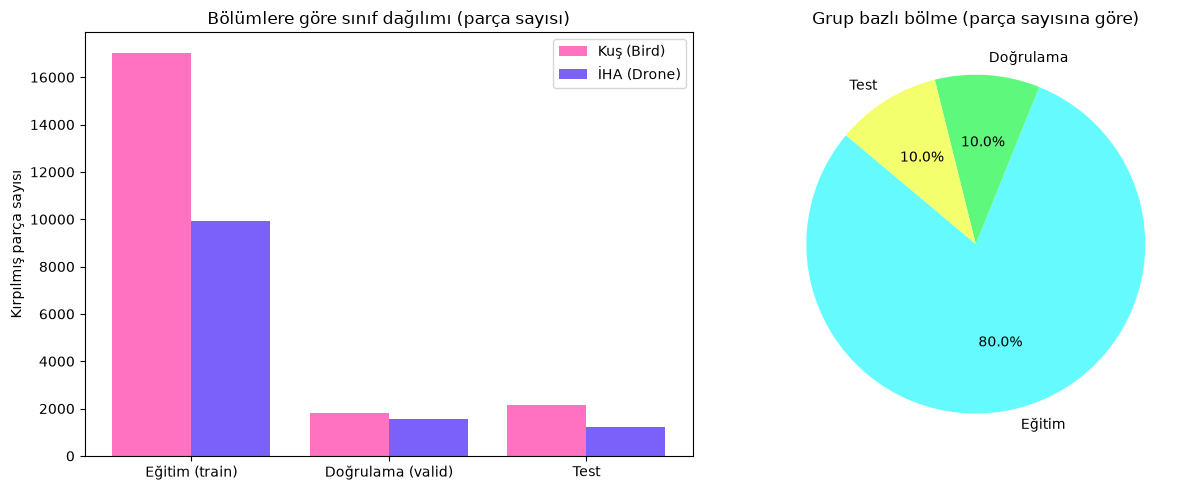

In [28]:
# BÖLÜM x SINIF ve VERİ SETİ x BÖLÜM
bolumler = ["train", "valid", "test"]
tablo = {}
for b in bolumler:
    tablo[b] = {"bird": 0, "drone": 0}
for dosya_yolu, isim, sinif, bolum in kayit_listesi:
    tablo[bolum][sinif] += 1

print("BÖLÜM x SINIF:")
for b in bolumler:
    toplam_b = tablo[b]["bird"] + tablo[b]["drone"]
    print(f"  {b:<6} toplam {toplam_b:<6} (%{100 * toplam_b / len(kayit_listesi):.1f})  kuş {tablo[b]['bird']:<6} İHA {tablo[b]['drone']}")
toplam_kus = tablo["train"]["bird"] + tablo["valid"]["bird"] + tablo["test"]["bird"]
toplam_iha = tablo["train"]["drone"] + tablo["valid"]["drone"] + tablo["test"]["drone"]
print(f"NİHAİ HAVUZ: {toplam_kus} kuş, {toplam_iha} İHA")

print("\nVERİ SETİ x BÖLÜM x SINIF:")
for isim in kullanilacak_veri_setleri:
    for b in bolumler:
        kus = 0
        drone = 0
        for dosya_yolu, k_isim, sinif, bolum in kayit_listesi:
            if k_isim == isim and bolum == b:
                if sinif == "bird":
                    kus += 1
                else:
                    drone += 1
        print(f"  {isim} / {b:<6}: kuş {kus:<6} İHA {drone}")

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
x_konum = [0, 1, 2]
plt.bar([k - 0.2 for k in x_konum], [tablo[b]["bird"] for b in bolumler], width=0.4, label="Kuş (Bird)", color="#FF71C1")
plt.bar([k + 0.2 for k in x_konum], [tablo[b]["drone"] for b in bolumler], width=0.4, label="İHA (Drone)", color="#7B61FA")
plt.xticks(x_konum, ["Eğitim (train)", "Doğrulama (valid)", "Test"])
plt.ylabel("Kırpılmış parça sayısı")
plt.title("Bölümlere göre sınıf dağılımı (parça sayısı)")
plt.legend()
plt.subplot(1, 2, 2)
plt.pie([tablo[b]["bird"] + tablo[b]["drone"] for b in bolumler], labels=["Eğitim", "Doğrulama", "Test"],
        autopct="%1.1f%%", colors=["#65FBFE", "#5EF87D", "#F3FF6D"], startangle=140)
plt.title("Grup bazlı bölme (parça sayısına göre)")
plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel5_nihai_durum.png", dpi=150)
plt.show()

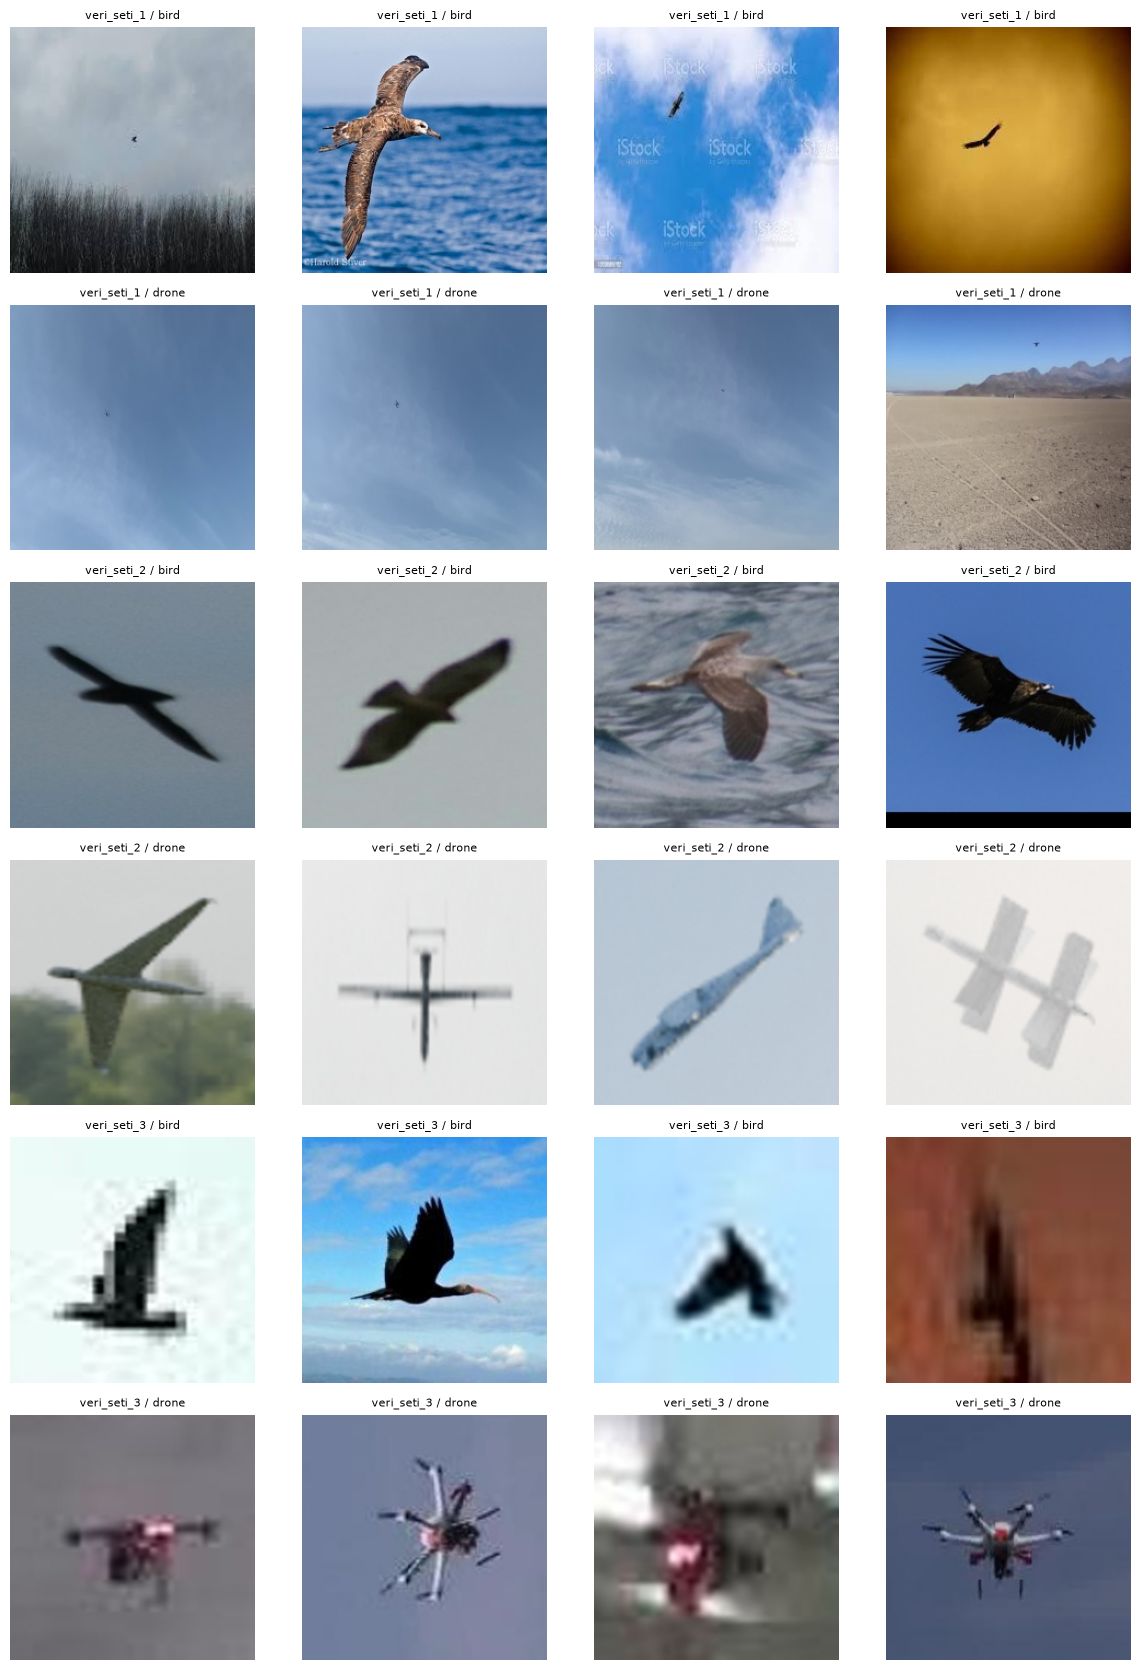

In [29]:
# 6b) GÖRSEL KONTROL: her veri seti ve sınıftan 4 parça
satir_sayisi = len(kullanilacak_veri_setleri) * 2
plt.figure(figsize=(12, 2.8 * satir_sayisi))
sira = 0
for isim in kullanilacak_veri_setleri:
    for sinif in ["bird", "drone"]:
        secilenler = []
        for dosya_yolu, k_isim, k_sinif, bolum in kayit_listesi:
            if k_isim == isim and k_sinif == sinif:
                secilenler.append(dosya_yolu)
        secilenler = random.sample(secilenler, min(4, len(secilenler)))
        for k in range(len(secilenler)):
            plt.subplot(satir_sayisi, 4, sira * 4 + k + 1)
            plt.imshow(Image.open(secilenler[k]))
            plt.title(f"{isim} / {sinif}", fontsize=8)
            plt.axis("off")
        sira += 1
plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel6_on_isleme_kontrol.png", dpi=120)
plt.show()

In [30]:
# ARKA PLAN KESTİRMESİ KONTROLÜ: parçaların ne kadarı (neredeyse) beyaz piksel?
# Bir sınıfın parçalarında beyaz arka plan çok daha fazlaysa, model kuşu/İHA'yı nesneden değil arka plandan tanır. ezberi engellemek için
import numpy as np

print("Beyaz piksel oranı (ortalama; parça başına en fazla 300 örnek):")
beyaz_ortalama = {}
for isim in kullanilacak_veri_setleri:
    for sinif in ["bird", "drone"]:
        yollar = []
        for dosya_yolu, k_isim, k_sinif, bolum in kayit_listesi:
            if k_isim == isim and k_sinif == sinif:
                yollar.append(dosya_yolu)
        yollar = random.sample(yollar, min(300, len(yollar)))
        if len(yollar) == 0:
            continue
        toplam_oran = 0
        for yol in yollar:
            dizi = np.array(Image.open(yol).convert("RGB"))
            beyaz_oran = float((dizi.min(axis=2) > 235).mean())    # üç kanalı da 235'ten büyük pikseller
            toplam_oran += beyaz_oran
        beyaz_ortalama[(isim, sinif)] = toplam_oran / len(yollar)
        print(f"  {isim} / {sinif}: %{100 * beyaz_ortalama[(isim, sinif)]:.1f}")
for isim in kullanilacak_veri_setleri:
    if (isim, "bird") in beyaz_ortalama and (isim, "drone") in beyaz_ortalama:
        fark = abs(beyaz_ortalama[(isim, "bird")] - beyaz_ortalama[(isim, "drone")])
        if fark > 0.15:
            print(f"UYARI: {isim}: iki sınıfın beyaz piksel oranı arasında %{100 * fark:.0f} fark var; arka plan kestirmesi riski.")

Beyaz piksel oranı (ortalama; parça başına en fazla 300 örnek):
  veri_seti_1 / bird: %6.6
  veri_seti_1 / drone: %1.6
  veri_seti_2 / bird: %3.3
  veri_seti_2 / drone: %6.6
  veri_seti_3 / bird: %14.2
  veri_seti_3 / drone: %4.0
